**Universidade Federal do Rio Grande do Norte**

**Disciplina:** PPGEEC2327 - Tópicos Especiais em Processamento Inteligente da Informação

**Discente:** José Augusto Agripino de Oliveira

# Deconvolução cega com redes neurais recorrentes (RNN)

Laboratório: [Blind Deconvolution by Vanilla Recurrent Neural Network](http://utam.gg.utah.edu/Classes/ML/LAB1/Chapter.CNN.RNN/RNN_lab.html) (S. Feng).

Um traço sísmico é modelado como a convolução da refletividade $r(t)$ com a wavelet $w(t)$:

$$x(t) = (w * r)(t) = \sum_k w(k)\,r(t-k).$$

A **deconvolução** faz o caminho inverso: recupera os *spikes* de $r$ a partir do sismograma $x$. Ela é **cega** porque a wavelet não é dada à rede. A RNN aprende o filtro inverso só a partir de pares (sismograma, refletividade).

O `RNN_deconv.m` do lab gera 2000 amostras de refletividade, com um spike de amplitude aleatória em $[-1, 1]$ a cada 20 amostras, e faz a convolução com uma Ricker de 1 Hz ($\Delta t = 0{,}1$ s). Depois treina `layrecnet(1, 10, 'trainlm')`: uma RNN com 10 neurônios tanh, realimentados com atraso de uma amostra, e uma saída linear:

$$\mathbf h(t) = \tanh\big(\mathbf W x(t) + \mathbf R\,\mathbf h(t-1) + \mathbf b\big),\qquad \hat r(t) = \mathbf v^\top \mathbf h(t) + c .$$

**O que a seção 6 (*Questions*) do lab pede:**

1. Usar a refletividade como entrada e o sismograma como saída, isto é, usar a RNN para imitar a convolução. Como fica o resultado? Por quê?
2. Modificar a estrutura e os parâmetros da RNN e ver como eles mudam o resultado.
3. O lab usa a RNN convencional, sem portas. Uma calculadora binária treinada com LSTM está em `RNN_binary_lstm.m`.

A seção 1 reproduz o lab. As seções 2, 3 e 4 respondem às tarefas (1), (2) e (3), e a seção 5 reúne as conclusões.

In [1]:
import os
os.environ.setdefault('OPENBLAS_NUM_THREADS', '1')   # matrizes pequenas: com várias threads, o OpenBLAS ficou ~100x mais lento
import time
import warnings
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import as_strided
from scipy.linalg import cho_factor, cho_solve
from IPython.display import display

warnings.filterwarnings('ignore', message='.*use of fork.*', category=DeprecationWarning)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
                     'legend.frameon': False})
SEMENTES = range(5)                                   # inicializações por configuração
N_PROC = max(1, (os.cpu_count() or 2) - 2)            # processos de treino em paralelo (1 = em série)
if 'fork' not in mp.get_all_start_methods():
    N_PROC = 1
COR = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']   # mesma paleta dos exercícios anteriores
VERD = '#8a8984'                                      # série verdadeira (neutra) sob a previsão colorida
print(f'{N_PROC} processos de treino')

14 processos de treino


## 1. Reprodução do lab: deconvolução com a RNN

### 1.1 Wavelet e dados

O `ricker.m` devolve a Ricker a partir de $1/f$ segundos antes do pico. Com $f = 1$ Hz e $\Delta t = 0{,}1$ s, o pico fica na amostra 10. O corte `x_conv(11:2010)` do `RNN_deconv.m` alinha o pico da wavelet com cada spike. Assim:

$$x(t) = \sum_{k=-10}^{499} w(k)\, r(t-k),$$

ou seja, o sismograma no instante $t$ depende da refletividade até 10 amostras **no futuro**, $r(t+1), \dots, r(t+10)$.

wavelet: 510 amostras, pico na amostra 10; treino: 2000 amostras; teste: 200 amostras


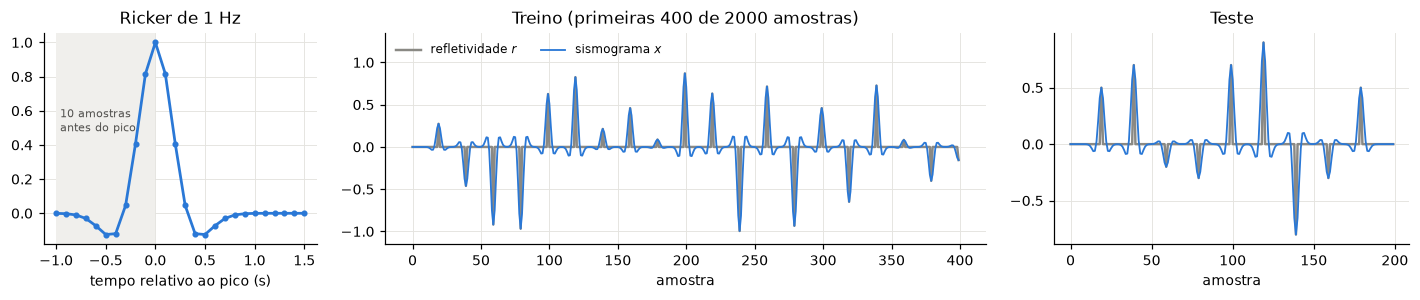

In [2]:
def ricker(np_, fr, dt):
    # tradução de ricker.m: Ricker de frequência fr, a partir de 1/fr s antes do pico
    npt = np_ * dt
    t = np.linspace(-npt / 2, npt / 2, int(round(npt / dt)) + 1)        # (-npt/2):dt:npt/2
    rick1 = (1 - t * t * fr**2 * np.pi**2) * np.exp(-t**2 * np.pi**2 * fr**2)
    return rick1[int(round(np_ / 2)) - int(round(1 / fr / dt)):np_]     # rick1(round(np/2)-round(1/fr/dt)+1 : np)


def sismograma(r, w, pico):
    # convolução cortada para que o pico da wavelet caia sobre cada spike (no .m: x_conv(11:2010), pico = 10)
    return np.convolve(w, r)[pico:pico + len(r)]


DT = 0.1
wav = ricker(1000, 1, DT)
PICO = int(np.argmax(wav))

# treino (RNN_deconv.m): spike de amplitude U(-1, 1) a cada 20 amostras
rng = np.random.default_rng(0)
r_tr = np.zeros(2000)
r_tr[19::20] = 2 * rng.random(100) - 1         # y(1, 20*ii) = 2*rand(1) - 1  (o MATLAB indexa a partir de 1)
x_tr = sismograma(r_tr, wav, PICO)

# teste (RNN_deconv.m): 9 spikes fixos
r_te = np.zeros(200)
r_te[19:180:20] = [0.5, 0.7, -0.2, -0.3, 0.7, 0.9, -0.8, -0.3, 0.5]
x_te = sismograma(r_te, wav, PICO)
print(f'wavelet: {len(wav)} amostras, pico na amostra {PICO}; treino: {len(x_tr)} amostras; teste: {len(x_te)} amostras')

fig, ax = plt.subplots(1, 3, figsize=(13, 2.8), gridspec_kw=dict(width_ratios=[1, 2.2, 1.3]))
tw = (np.arange(len(wav)) - PICO) * DT
ax[0].axvspan(tw[0], 0, color='#f0efec', lw=0)
ax[0].plot(tw[:26], wav[:26], color=COR[0], lw=1.8, marker='o', ms=3)
ax[0].text(-0.96, 0.62, '10 amostras\nantes do pico', color='#52514e', fontsize=7.5, va='top')
ax[0].set(title='Ricker de 1 Hz', xlabel='tempo relativo ao pico (s)')
for a, x, r, n, t in [(ax[1], x_tr, r_tr, 400, 'Treino (primeiras 400 de 2000 amostras)'), (ax[2], x_te, r_te, 200, 'Teste')]:
    a.plot(r[:n], color=VERD, lw=1.6, label='refletividade $r$')
    a.plot(x[:n], color=COR[0], lw=1.2, label='sismograma $x$')
    a.set(title=t, xlabel='amostra')
ax[1].set_ylim(-1.15, 1.35)
ax[1].legend(loc='upper left', ncol=2, fontsize=8)
plt.tight_layout()

### 1.2 A rede recorrente (`layrecnet` + `trainlm`)

A classe abaixo implementa:

* `propaga`: a propagação direta e, quando pedido, o jacobiano por RTRL. Para cada camada $l$:
  $\mathbf S_l(t) = \partial \mathbf h_l(t)/\partial\boldsymbol\theta = f'(\mathbf a_l)\odot\big[\partial \mathbf a_l/\partial\boldsymbol\theta|_{\text{direto}} + \mathbf W_l\,\mathbf S_{l-1}(t) + \sum_d \mathbf R_{l,d}\,\mathbf S_l(t-d)\big]$.
* `treinar`: Levenberg–Marquardt (`'lm'`, como o `trainlm`) ou gradiente descendente (`'gd'`, como o `traingd`). Também cuida da normalização, da divisão treino/validação e da parada antecipada.
* `atraso_saida = D`: a rede só precisa responder $\hat y(t-D)$ no instante $t$, ou seja, ela vê $D$ amostras "do futuro". O lab usa $D = 0$.

In [3]:
class MapMinMax:
    # mapminmax do MATLAB: leva [min, max] para [-1, 1]
    def __init__(self, v):
        self.lo, self.hi = float(v.min()), float(v.max())

    def __call__(self, v):
        return 2 * (v - self.lo) / (self.hi - self.lo) - 1

    def inv(self, v):
        return (v + 1) / 2 * (self.hi - self.lo) + self.lo


class RedeRecorrente:
    # layrecnet: camadas tanh com realimentação atrasada (atrasos) + saída linear

    def __init__(self, ocultas=(10,), atrasos=(1,), semente=0):
        self.H, self.atrasos = tuple(ocultas), tuple(atrasos)
        self.D = max(self.atrasos, default=0)
        self.n_in = [1] + list(self.H[:-1])                       # entradas de cada camada
        blocos = []
        for l, H in enumerate(self.H):
            blocos += [(f'W{l}', (H, self.n_in[l]))] + [(f'R{l}_{d}', (H, H)) for d in self.atrasos] + [(f'b{l}', (H,))]
        blocos += [('V', (1, self.H[-1])), ('c', (1,))]
        self.idx, o = {}, 0
        for nome, forma in blocos:
            self.idx[nome] = (o, forma)
            o += int(np.prod(forma))
        self.P = o                                                # número de parâmetros
        # inicialização tipo Nguyen-Widrow (initnw) nas camadas ocultas e U(-1, 1) na saída
        rng = np.random.default_rng(semente)
        th = np.zeros(self.P)
        for l, H in enumerate(self.H):
            fan = self.n_in[l] + H * len(self.atrasos)
            beta = 0.7 * H ** (1 / fan)
            M = rng.uniform(-1, 1, (H, fan))
            M *= beta / np.linalg.norm(M, axis=1, keepdims=True)
            self._set(th, f'W{l}', M[:, :self.n_in[l]])
            for k, d in enumerate(self.atrasos):
                self._set(th, f'R{l}_{d}', M[:, self.n_in[l] + k * H:self.n_in[l] + (k + 1) * H])
            self._set(th, f'b{l}', rng.uniform(-beta, beta, H))
        self._set(th, 'V', rng.uniform(-1, 1, (1, self.H[-1])))
        self._set(th, 'c', rng.uniform(-1, 1, 1))
        self.th = th

    def _set(self, th, nome, val):
        o, forma = self.idx[nome]
        th[o:o + int(np.prod(forma))] = np.ravel(val)

    def _get(self, th, nome):
        o, forma = self.idx[nome]
        return th[o:o + int(np.prod(forma))].reshape(forma)

    def propaga(self, th, u, jac=False):
        T, D, P, L = len(u), self.D, self.P, len(self.H)
        W = [self._get(th, f'W{l}') for l in range(L)]
        R = [{d: self._get(th, f'R{l}_{d}') for d in self.atrasos} for l in range(L)]
        b = [self._get(th, f'b{l}') for l in range(L)]
        V, c = self._get(th, 'V')[0], self._get(th, 'c')[0]
        hs = [np.zeros((T + D, H)) for H in self.H]               # D linhas de estado inicial nulo antes de t = 0
        U = u[:, None]
        for t in range(T):                                        # 1) propagação direta
            inp = U[t]
            for l in range(L):
                a = W[l] @ inp + b[l]
                for d in self.atrasos:
                    a += R[l][d] @ hs[l][t + D - d]
                inp = hs[l][t + D] = np.tanh(a)
        y = hs[-1][D:] @ V + c
        if not jac:
            return y
        # 2) jacobiano por RTRL. As views 'diag' apontam os termos diretos da/dW, da/dR e da/db dentro de dA:
        #    elemento [i, j] -> dA[i, deslocamento + i*n + j]
        diag = lambda A, o, n: as_strided(A[:, o:], shape=(A.shape[0], n), strides=(A.strides[0] + n * A.strides[1], A.strides[1]))
        dA = [np.empty((H, P)) for H in self.H]
        S = [np.zeros((D + 1, H, P)) for H in self.H]             # buffer circular com S(t-D) ... S(t)
        der = [1 - h[D:] ** 2 for h in hs]                        # tanh'(a) = 1 - h^2
        vW = [diag(dA[l], self.idx[f'W{l}'][0], self.n_in[l]) for l in range(L)]
        vR = [{d: diag(dA[l], self.idx[f'R{l}_{d}'][0], self.H[l]) for d in self.atrasos} for l in range(L)]
        vb = [diag(dA[l], self.idx[f'b{l}'][0], 1) for l in range(L)]
        J = np.zeros((T, P))
        oV, oc = self.idx['V'][0], self.idx['c'][0]
        for t in range(T):
            inp, S_inp = U[t], None
            for l in range(L):
                A = dA[l]
                if l > 0:
                    np.matmul(W[l], S_inp, out=A)
                elif not self.atrasos:
                    A.fill(0.0)
                for k, d in enumerate(self.atrasos):
                    if l == 0 and k == 0:
                        np.matmul(R[l][d], S[l][(t - d) % (D + 1)], out=A)
                    else:
                        A += R[l][d] @ S[l][(t - d) % (D + 1)]
                    vR[l][d] += hs[l][t + D - d]
                vW[l] += inp
                vb[l] += 1.0
                S_inp = S[l][t % (D + 1)]
                np.multiply(A, der[l][t][:, None], out=S_inp)
                inp = hs[l][t + D]
            np.matmul(V, S_inp, out=J[t])
            J[t, oV:oV + len(inp)] += inp
            J[t, oc] += 1.0
        return y, J

    def treinar(self, x, alvo, **opcoes):
        with np.errstate(all='ignore'):          # redes que divergem geram overflow; o treino trata esses casos
            return self._treinar(x, alvo, **opcoes)

    def _treinar(self, x, alvo, metodo='lm', epocas=500, lr=0.05, divisao=(0.70, 0.15, 0.15), max_fail=6,
                 mu=1e-3, mu_dec=0.1, mu_inc=10.0, mu_max=1e10, min_grad=1e-6, meta=1e-15, atraso_saida=0, semente=0):
        self.nx, self.ny, self.atraso_saida = MapMinMax(x), MapMinMax(alvo), atraso_saida
        T, Ds = len(x), atraso_saida
        u = np.concatenate([self.nx(x), np.zeros(Ds)])            # a saída da amostra n sai no instante n + Ds
        tn = self.ny(alvo)
        perm = np.random.default_rng(semente).permutation(T)      # dividerand, modo 'time'
        ntr = int(round(divisao[0] * T)) if divisao else T
        nva = int(round(divisao[1] * T)) if divisao else 0
        itr, iva = np.sort(perm[:ntr]), np.sort(perm[ntr:ntr + nva])
        mse = lambda o, ii: np.mean((o[ii + Ds] - tn[ii]) ** 2)
        th = self.th.copy()
        hist = {'treino': [], 'validacao': [], 'th': []}
        melhor, th_melhor, falhas, motivo = np.inf, th.copy(), 0, 'épocas'
        t0 = time.perf_counter()
        o, J = self.propaga(th, u, jac=True)
        for ep in range(epocas + 1):
            perf = mse(o, itr)
            pv = mse(o, iva) if len(iva) else perf
            hist['treino'].append(perf); hist['validacao'].append(pv); hist['th'].append(th.copy())
            if pv < melhor:
                melhor, th_melhor, falhas, self.epoca_melhor = pv, th.copy(), 0, ep
            else:
                falhas += 1
            Jt, e = J[itr + Ds], o[itr + Ds] - tn[itr]
            g = 2 * Jt.T @ e / len(itr)                           # gradiente do EQM
            if ep == epocas:
                break
            if not np.isfinite(perf):
                motivo = 'divergiu'; break
            if perf <= meta:
                motivo = 'meta'; break
            if np.linalg.norm(g) < min_grad:
                motivo = 'gradiente mínimo'; break
            if len(iva) and falhas >= max_fail:
                motivo = 'validação'; break
            if metodo == 'lm':
                JJ, Je, aceito = Jt.T @ Jt, Jt.T @ e, False
                while mu <= mu_max:                               # aumenta mu até o passo reduzir o erro
                    try:
                        dth = -cho_solve(cho_factor(JJ + mu * np.eye(self.P)), Je)
                    except (np.linalg.LinAlgError, ValueError):       # matriz não positiva definida ou com inf/NaN
                        mu *= mu_inc
                        continue
                    if mse(self.propaga(th + dth, u), itr) < perf:
                        th, mu, aceito = th + dth, mu * mu_dec, True
                        break
                    mu *= mu_inc
                if not aceito:
                    motivo = 'mu máximo'; break
            else:                                                 # traingd
                th = th - lr * g
            o, J = self.propaga(th, u, jac=True)
        self.th, self.hist, self.epocas, self.motivo = th_melhor, hist, ep, motivo
        self.val, self.tempo = melhor, time.perf_counter() - t0
        return self

    def __call__(self, x, th=None):
        th = self.th if th is None else th
        u = np.concatenate([self.nx(x), np.zeros(self.atraso_saida)])
        with np.errstate(all='ignore'):
            return self.ny.inv(self.propaga(th, u)[self.atraso_saida:])


nmse = lambda prev, alvo: float(np.sum((prev - alvo) ** 2) / np.sum(alvo ** 2))
melhor = lambda redes: min(redes, key=lambda r: r.val)          # escolha pela validação


def _treina(tarefa):
    nome, estrutura, treino, entrada, alvo, semente = tarefa
    return RedeRecorrente(semente=semente, **estrutura).treinar(entrada, alvo, semente=semente, **treino)


def treina_lote(configs, entrada=None, alvo=None, sementes=SEMENTES):
    # Treina cada configuração {nome: dict} a partir de todas as sementes, em paralelo.
    # Devolve {nome: [rede da semente 0, rede da semente 1, ...]}.
    tarefas = []
    for nome, cfg in configs.items():
        cfg = dict(cfg)
        e, a = cfg.pop('entrada', entrada), cfg.pop('alvo', alvo)
        estrutura = {k: cfg.pop(k) for k in ('ocultas', 'atrasos') if k in cfg}
        tarefas += [(nome, estrutura, cfg, e, a, s) for s in sementes]
    # as tarefas mais demoradas primeiro, para os processos terminarem juntos
    custo = lambda t: RedeRecorrente(**t[1]).P * (8 if t[2].get('metodo') == 'gd' or 'divisao' in t[2] or t[2].get('atraso_saida', 0) >= 10 else 1)
    ordem = sorted(range(len(tarefas)), key=lambda i: -custo(tarefas[i]))
    if N_PROC > 1:
        with ProcessPoolExecutor(N_PROC, mp_context=mp.get_context('fork')) as ex:
            redes = list(ex.map(_treina, [tarefas[i] for i in ordem]))
    else:
        redes = [_treina(tarefas[i]) for i in ordem]
    saida = {nome: [None] * len(sementes) for nome in configs}
    for i, rede in zip(ordem, redes):
        saida[tarefas[i][0]][list(sementes).index(tarefas[i][5])] = rede
    return saida


def fmt(v):
    return f'{v:.4f}' if 1e-3 <= abs(v) < 100 else f'{v:.1e}'


def tabela_sementes(redes, ent_tr, alvo_tr, ent_te, alvo_te):
    esc = melhor(redes)
    return pd.DataFrame([{'semente': s, 'épocas': r.epocas, 'parada': r.motivo, 'EQM validação (normalizado)': fmt(r.val),
                          'NMSE treino': fmt(nmse(r(ent_tr), alvo_tr)), 'NMSE teste': fmt(nmse(r(ent_te), alvo_te)),
                          'tempo (s)': f'{r.tempo:.1f}', 'escolhida': '◀' if r is esc else ''}
                         for s, r in zip(SEMENTES, redes)]).set_index('semente')

### 1.3 Treino e resultado

`layrecnet(1, 10, 'trainlm')` treinada a partir de 5 inicializações:

In [4]:
t0 = time.perf_counter()
lab = treina_lote({'lab': {}}, x_tr, r_tr)['lab']
base = melhor(lab)
print(f'{len(lab)} redes treinadas em {time.perf_counter() - t0:.0f} s; {base.P} parâmetros')
display(tabela_sementes(lab, x_tr, r_tr, x_te, r_te))

5 redes treinadas em 8 s; 131 parâmetros


,épocas,parada,EQM validação (normalizado),NMSE treino,NMSE teste,tempo (s),escolhida
semente,,,,,,,
0,29,validação,0.0020,0.0718,0.2166,1.6,
1,144,validação,6.4e-05,0.0017,0.0048,7.5,
2,37,validação,6.4e-05,0.0039,0.0038,2.0,
3,92,validação,1.2e-04,0.0048,0.0048,4.9,
4,54,validação,4.9e-05,0.0021,0.0143,2.9,◀


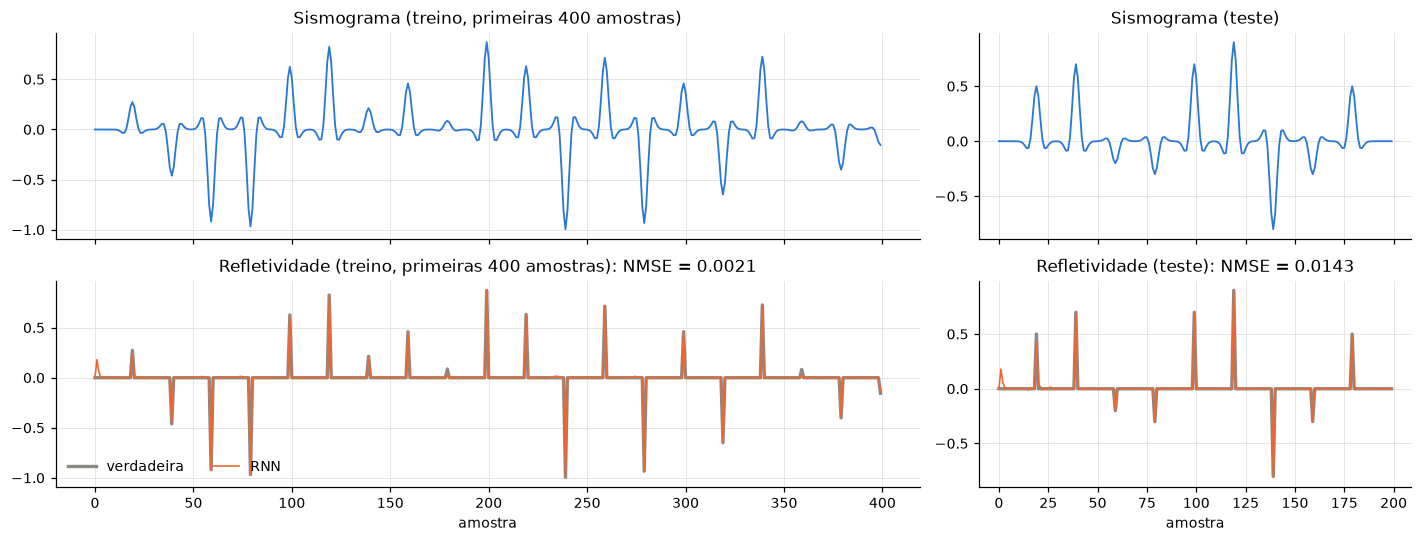

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 5), sharex='col', gridspec_kw=dict(width_ratios=[2, 1]))
for j, (x, r, n, nome) in enumerate([(x_tr, r_tr, 400, 'treino, primeiras 400 amostras'), (x_te, r_te, 200, 'teste')]):
    ax[0, j].plot(x[:n], color=COR[0], lw=1.2)
    ax[0, j].set_title(f'Sismograma ({nome})')
    ax[1, j].plot(r[:n], color=VERD, lw=2.2, label='verdadeira')
    ax[1, j].plot(base(x)[:n], color=COR[1], lw=1.1, label='RNN')
    ax[1, j].set(title=f'Refletividade ({nome}): NMSE = {nmse(base(x), r):.4f}', xlabel='amostra')
ax[1, 0].legend(loc='lower left', ncol=2)
plt.tight_layout()


**Resultado.** A rede escolhida pela validação (semente 4) recupera os nove spikes do teste com posição, sinal e amplitude quase exatos: NMSE de 0,0143 no teste e 0,0021 no treino. É o resultado da Fig. 1 do lab.

O resultado depende da inicialização: o NMSE de teste vai de 0,0038 a 0,22 entre as 5 sementes (a semente 0 parou cedo, após 29 épocas, num mínimo pior). Por isso, nas seções 2 e 3, cada configuração também é treinada a partir de 5 inicializações.

## 2. Tarefa (1): a RNN imitando a convolução

Agora a entrada é a refletividade e o alvo é o sismograma. A rede, os dados e o treino são os mesmos da seção 1.

Para explicar o resultado, já são treinadas também versões com **atraso de saída** $D = 5$ e $D = 10$: no instante $t$, a rede responde $\hat x(t-D)$, ou seja, ela pode ver $D$ amostras da refletividade além do instante que está prevendo. A seção 2.1 usa essas versões para testar a explicação.

In [6]:
t0 = time.perf_counter()
conv = treina_lote({D: dict(atraso_saida=D) for D in (0, 5, 10)}, r_tr, x_tr)
print(f'{sum(map(len, conv.values()))} redes treinadas em {time.perf_counter() - t0:.0f} s')
conv0 = melhor(conv[0])
display(tabela_sementes(conv[0], r_tr, x_tr, r_te, x_te))

15 redes treinadas em 27 s


,épocas,parada,EQM validação (normalizado),NMSE treino,NMSE teste,tempo (s),escolhida
semente,,,,,,,
0,2,mu máximo,0.4649,9.5556,10.9299,0.3,
1,29,validação,0.0097,0.3183,0.3164,2.5,◀
2,14,validação,0.0139,0.3205,0.3228,1.4,
3,11,validação,0.0208,0.3212,0.3174,1.1,
4,1,mu máximo,0.9282,19.9391,25.6160,0.2,


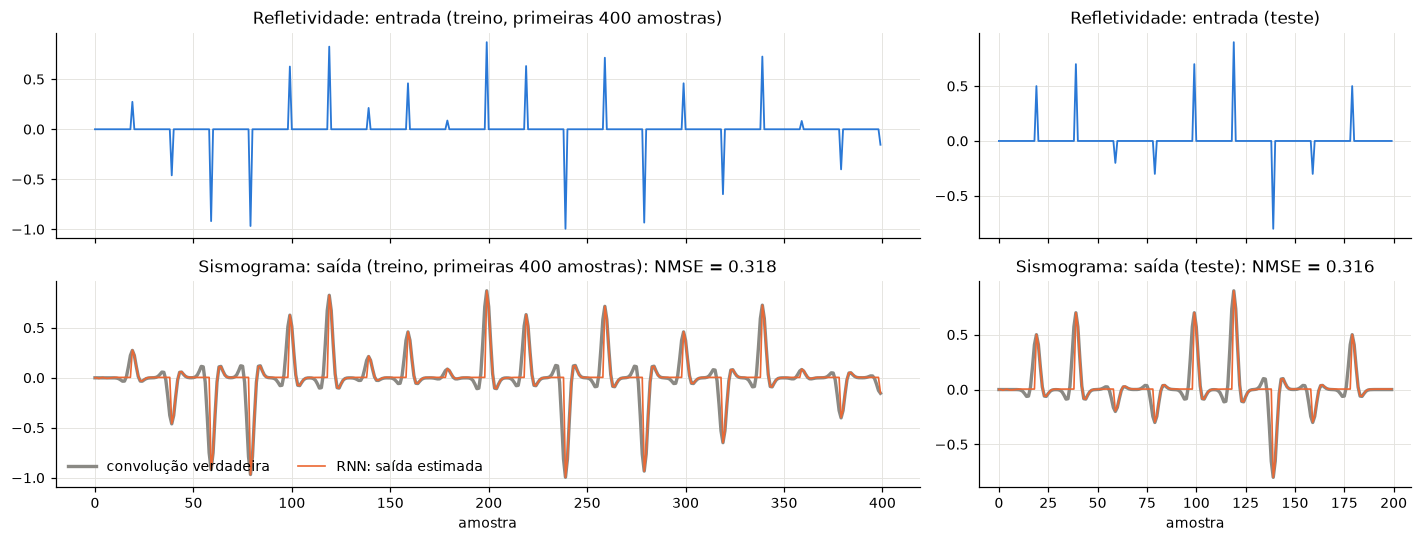

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 5), sharex='col', gridspec_kw=dict(width_ratios=[2, 1]))
for j, (x, r, n, nome) in enumerate([(x_tr, r_tr, 400, 'treino, primeiras 400 amostras'), (x_te, r_te, 200, 'teste')]):
    ax[0, j].plot(r[:n], color=COR[0], lw=1.2)
    ax[0, j].set_title(f'Refletividade: entrada ({nome})')
    ax[1, j].plot(x[:n], color=VERD, lw=2.2, label='convolução verdadeira')
    ax[1, j].plot(conv0(r)[:n], color=COR[1], lw=1.1, label='RNN: saída estimada')
    ax[1, j].set(title=f'Sismograma: saída ({nome}): NMSE = {nmse(conv0(r), x):.3f}', xlabel='amostra')
ax[1, 0].legend(loc='lower left', ncol=2)
plt.tight_layout()

**Resultado.** No caso causal ($D = 0$), duas das cinco inicializações falharam por "mu máximo": o Levenberg–Marquardt aumentou $\mu$ até o limite sem achar um passo que reduzisse o erro. As outras três convergiram para NMSE próximo de 0,32 no treino e no teste. A RNN reproduz bem o pico e a parte da wavelet que ocorre depois do spike, mas não consegue antecipar a parte que ocorre antes dele.

### 2.1 Por quê? Causalidade

Uma RNN unidirecional é **causal**: no instante $t$, ela depende apenas de $r(0), \dots, r(t)$. Porém, devido à Ricker de fase zero, o sismograma começa a variar até 10 amostras antes do spike. Para reproduzir essa parte, a rede precisaria conhecer valores futuros da refletividade. Com atraso de saída $D = 10$, ela recebe essa informação e consegue reproduzir a wavelet completa. A tabela mostra o NMSE de teste das versões treinadas acima:

In [8]:
display(pd.DataFrame([{'atraso de saída': f'D = {D}', 'NMSE teste (rede escolhida)': fmt(nmse(melhor(redes)(r_te), x_te)),
                       'NMSE teste (mediana das 5)': fmt(np.median([nmse(r(r_te), x_te) for r in redes]))}
                      for D, redes in conv.items()]).set_index('atraso de saída'))

,NMSE teste (rede escolhida),NMSE teste (mediana das 5)
atraso de saída,,
D = 0,0.3164,0.3228
D = 5,0.0028,0.0023
D = 10,2.1e-06,0.0020


**Por que a deconvolução funciona melhor que a convolução com $D = 0$?** Na deconvolução, o alvo $r(t)$ é um spike no pico da wavelet. Quando esse pico aparece no sismograma, a rede já observou o flanco de subida e consegue estimar sua amplitude. Na convolução, parte da saída ocorre antes do spike na entrada; uma RNN causal não pode prever essa informação. O atraso de saída $D = 10$ remove essa limitação ao permitir que a rede veja amostras futuras da refletividade.

## 3. Tarefa (2): estrutura e parâmetros da RNN

A partir da configuração do lab (10 neurônios, atraso 1, uma camada, $D = 0$, `trainlm` com parada antecipada), cada experimento muda **um** item:

| grupo | o que muda |
|---|---|
| 3.1 neurônios | tamanho da camada oculta: 1, 2, 5, 10, 20 |
| 3.2 memória | atrasos da realimentação: nenhum (rede estática), 1, 1:2, 1:3 |
| 3.3 profundidade | uma camada `[10]` contra duas, `[5 5]` e `[10 10]` |
| 3.4 antecipação | atraso de saída $D$ = 0, 2, 5 |
| 3.5 treinamento | `trainlm` com e sem parada antecipada (100 % dos dados no treino); `traingd` com lr = 0,05 (o valor do lab) e lr = 0,5 |

Cada configuração é treinada a partir das 5 inicializações. A tabela mostra o NMSE de teste da rede escolhida pela validação, a mediana das 5 e quantas convergiram (NMSE de treino < 0,05). Todas as redes são treinadas de uma vez, em paralelo.

In [9]:
LAB = None   # reaproveita as redes da seção 1
EXPERIMENTOS = {
    '3.1 neurônios': {'H = 1': dict(ocultas=(1,)), 'H = 2': dict(ocultas=(2,)), 'H = 5': dict(ocultas=(5,)),
                      'H = 10 (lab)': LAB, 'H = 20': dict(ocultas=(20,))},
    '3.2 memória': {'sem recorrência': dict(atrasos=()), 'atraso 1 (lab)': LAB, 'atrasos 1:2': dict(atrasos=(1, 2)),
                    'atrasos 1:3': dict(atrasos=(1, 2, 3))},
    '3.3 profundidade': {'[10] (lab)': LAB, '[5 5]': dict(ocultas=(5, 5)), '[10 10]': dict(ocultas=(10, 10))},
    '3.4 antecipação': {'D = 0 (lab)': LAB, 'D = 2': dict(atraso_saida=2), 'D = 5': dict(atraso_saida=5)},
    '3.5 treinamento': {'trainlm (lab)': LAB, 'trainlm sem parada antecipada': dict(divisao=None),
                        'traingd, lr = 0,05': dict(metodo='gd', lr=0.05), 'traingd, lr = 0,5': dict(metodo='gd', lr=0.5)},
}
novas = {nome: cfg for grupo in EXPERIMENTOS.values() for nome, cfg in grupo.items() if cfg is not None}
t0 = time.perf_counter()
redes_exp = treina_lote(novas, x_tr, r_tr)
print(f'{sum(map(len, redes_exp.values()))} redes treinadas em {time.perf_counter() - t0:.0f} s')
redes_exp.update({nome: lab for grupo in EXPERIMENTOS.values() for nome, cfg in grupo.items() if cfg is None})


def resumo(grupo):
    linhas = []
    for nome in EXPERIMENTOS[grupo]:
        redes = redes_exp[nome]
        te = [nmse(r(x_te), r_te) for r in redes]
        tr = [nmse(r(x_tr), r_tr) for r in redes]
        linhas.append({'configuração': nome, 'parâmetros': redes[0].P, 'NMSE teste (escolhida)': fmt(nmse(melhor(redes)(x_te), r_te)),
                       'NMSE teste (mediana das 5)': fmt(np.median(te)), 'convergiram': f'{sum(t < 0.05 for t in tr)}/{len(redes)}',
                       'épocas (mediana)': int(np.median([r.epocas for r in redes])),
                       'tempo médio (s)': f'{np.mean([r.tempo for r in redes]):.1f}'})
    return pd.DataFrame(linhas).set_index('configuração')


for grupo in EXPERIMENTOS:
    print(grupo)
    display(resumo(grupo))

70 redes treinadas em 105 s
3.1 neurônios


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
H = 1,5,0.6364,0.6364,0/5,11,1.1
H = 2,11,0.4645,0.5878,0/5,21,4.9
H = 5,41,0.0012,0.0077,4/5,60,4.9
H = 10 (lab),131,0.0143,0.0048,4/5,54,3.8
H = 20,461,4.1e-05,0.0320,4/5,33,10.1


3.2 memória


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
sem recorrência,31,0.4884,0.4897,0/5,40,3.2
atraso 1 (lab),131,0.0143,0.0048,4/5,54,3.8
atrasos 1:2,231,5.7e-04,0.0046,5/5,59,16.0
atrasos 1:3,331,5.1e-06,0.0681,5/5,52,18.1


3.3 profundidade


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
[10] (lab),131,0.0143,0.0048,4/5,54,3.8
[5 5],96,4.0e-04,0.0023,4/5,50,15.1
[10 10],341,0.0532,0.0268,5/5,54,26.3


3.4 antecipação


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
D = 0 (lab),131,0.0143,0.0048,4/5,54,3.8
D = 2,131,2.3e-04,0.0233,4/5,38,5.4
D = 5,131,1.1e-04,0.0014,4/5,132,12.3


3.5 treinamento


,parâmetros,NMSE teste (escolhida),NMSE teste (mediana das 5),convergiram,épocas (mediana),tempo médio (s)
configuração,,,,,,
trainlm (lab),131,0.0143,0.0048,4/5,54,3.8
trainlm sem parada antecipada,131,5.1e-05,3.2e-04,4/5,500,39.8
"traingd, lr = 0,05",131,0.8190,0.6703,0/5,500,36.3
"traingd, lr = 0,5",131,3.4724,98.0612,0/5,6,0.5


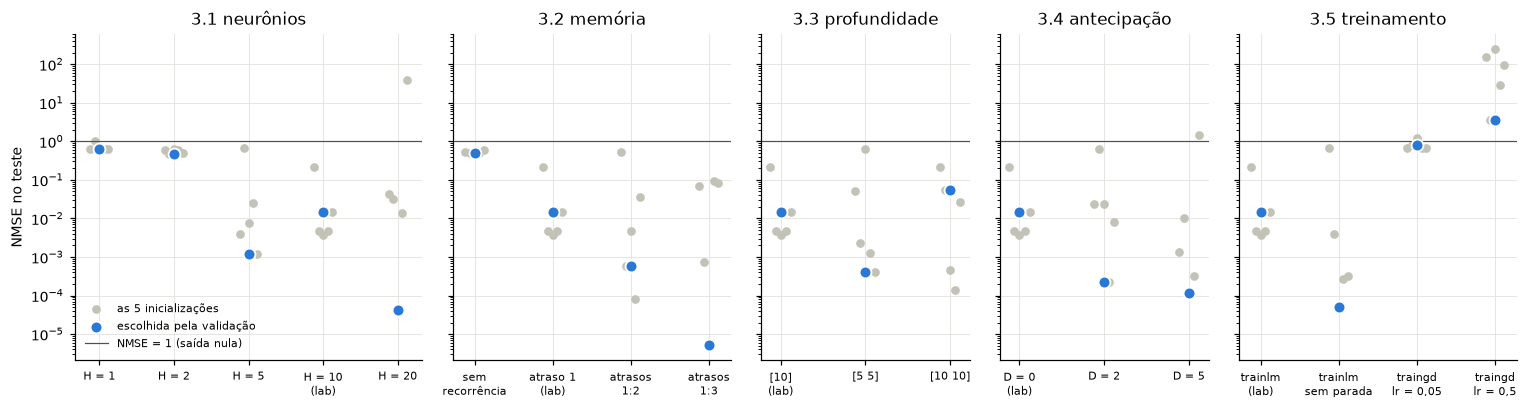

In [10]:
ROTULO = {'sem recorrência': 'sem\nrecorrência', 'atraso 1 (lab)': 'atraso 1\n(lab)', 'atrasos 1:2': 'atrasos\n1:2',
          'atrasos 1:3': 'atrasos\n1:3', 'trainlm (lab)': 'trainlm\n(lab)', 'trainlm sem parada antecipada': 'trainlm\nsem parada',
          'traingd, lr = 0,05': 'traingd\nlr = 0,05', 'traingd, lr = 0,5': 'traingd\nlr = 0,5'}
fig, ax = plt.subplots(1, 5, figsize=(14, 3.8), sharey=True, gridspec_kw=dict(width_ratios=[5, 4, 3, 3, 4]))
for a, (grupo, cfgs) in zip(ax, EXPERIMENTOS.items()):
    for i, nome in enumerate(cfgs):
        redes = redes_exp[nome]
        te = np.array([nmse(r(x_te), r_te) for r in redes])
        a.scatter(np.full(len(te), i) + np.linspace(-0.12, 0.12, len(te)), te, s=22, color='#c3c2b7', zorder=2,
                  label='as 5 inicializações' if i == 0 else None)
        a.scatter(i, nmse(melhor(redes)(x_te), r_te), s=60, color=COR[0], edgecolor='white', lw=1.2, zorder=3,
                  label='escolhida pela validação' if i == 0 else None)
    a.axhline(1, color='#52514e', lw=0.8, label='NMSE = 1 (saída nula)' if a is ax[0] else None)
    a.set_xticks(range(len(cfgs)), [ROTULO.get(c, c.replace(' (lab)', '\n(lab)')) for c in cfgs], fontsize=7.5)
    a.set_title(grupo)
ax[0].set_yscale('log')
ax[0].set_ylabel('NMSE no teste')
ax[0].legend(loc='lower left', fontsize=7.5)
plt.tight_layout()

Previsões no conjunto de teste da rede escolhida em algumas configurações:

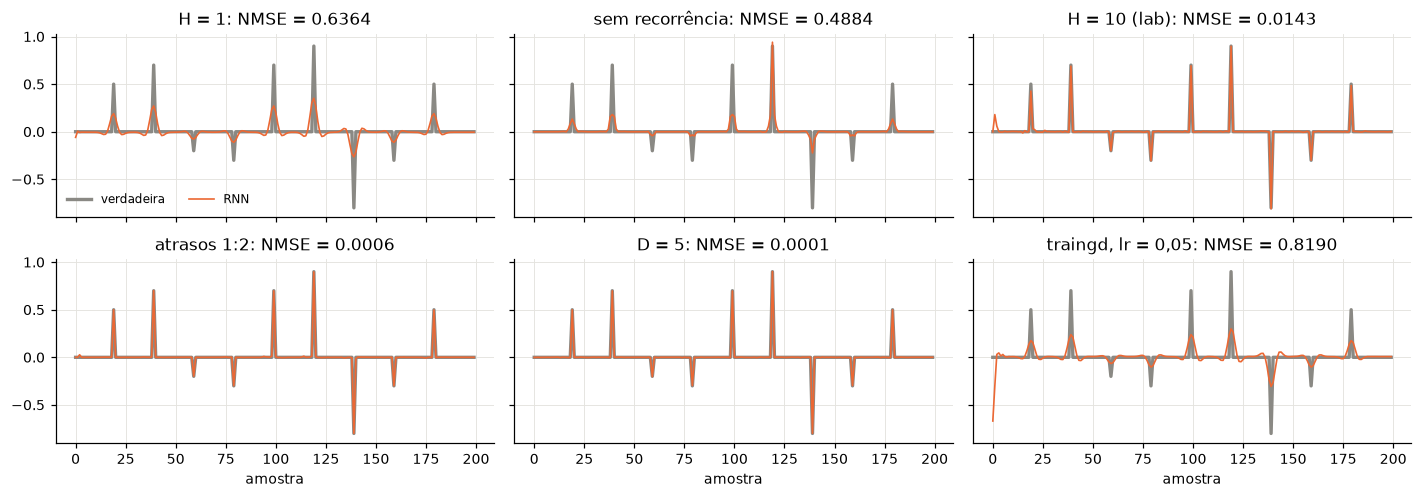

In [11]:
mostrar = ['H = 1', 'sem recorrência', 'H = 10 (lab)', 'atrasos 1:2', 'D = 5', 'traingd, lr = 0,05']
fig, ax = plt.subplots(2, 3, figsize=(13, 4.6), sharex=True, sharey=True)
for a, nome in zip(ax.flat, mostrar):
    p = melhor(redes_exp[nome])(x_te)
    a.plot(r_te, color=VERD, lw=2.2, label='verdadeira')
    a.plot(p, color=COR[1], lw=1.1, label='RNN')
    a.set_title(f'{nome}: NMSE = {nmse(p, r_te):.4f}')
ax[0, 0].legend(loc='lower left', ncol=2, fontsize=8)
for a in ax[1]:
    a.set_xlabel('amostra')
plt.tight_layout()

**3.1 Neurônios.** Com 1 ou 2 neurônios, nenhuma inicialização converge (NMSE de 0,46 a 0,64). A rede só produz spikes achatados (no painel *H = 1*, os picos saem com cerca de 30 % da amplitude), porque não tem graus de liberdade para manter o pico e cancelar os lobos laterais ao mesmo tempo. A partir de 5 neurônios o problema está resolvido: 4 de 5 inicializações convergem, e a rede escolhida tem NMSE entre $10^{-3}$ e $10^{-5}$.

Mais neurônios baixam o melhor erro (H = 20: $4\times10^{-5}$), mas não a mediana, e custam mais. O número de parâmetros cresce com $H^2$ (131 com H = 10, 461 com H = 20), e cada passo do LM resolve um sistema $P\times P$.

**3.2 Memória.** Sem realimentação, a rede é estática: $\hat r(t)$ depende só de $x(t)$, e uma amostra isolada não diz se é o pico de um evento fraco ou o flanco de um evento forte. Só o spike mais forte sai razoável, os outros saem muito atenuados (NMSE ≈ 0,49, nenhuma inicialização converge).

Com mais atrasos ($\mathbf R_1\mathbf h(t-1) + \mathbf R_2\mathbf h(t-2) + \dots$), a rede acessa diretamente estados mais antigos. As 5 inicializações convergem, e o erro da rede escolhida cai para $6\times10^{-4}$ (atrasos 1:2) e $5\times10^{-6}$ (atrasos 1:3). O custo é 1,8 a 2,5 vezes mais parâmetros e 3 a 4 vezes mais tempo de treino. Nesse grupo a mediana não melhora (0,005 e 0,07): o ajuste ao treino é muito bom em todas as inicializações, mas a generalização para o teste varia mais entre elas.

**3.3 Profundidade.** Duas camadas não trouxeram ganho sistemático. A `[5 5]`, com menos parâmetros que a `[10]` (96 contra 131), chegou a $4\times10^{-4}$. A `[10 10]` convergiu em todas as inicializações, mas a rede escolhida generalizou pior (0,053). Neste problema a profundidade não é o gargalo: uma camada com 5 a 10 neurônios já tem capacidade de sobra.

**3.4 Antecipação.** Deixar a rede olhar 2 ou 5 amostras à frente reduz o erro da rede escolhida em cerca de 2 ordens de grandeza (de 0,0143 para $2\times10^{-4}$ e $1\times10^{-4}$), sem nenhum parâmetro a mais. Com $D > 0$, a rede também vê o flanco de **descida** antes de decidir se aquele instante era o pico, em vez de deduzir isso só pela forma do flanco de subida. O custo é uma latência de $D$ amostras, irrelevante em processamento sísmico, que é feito depois da aquisição.

### 3.5 Algoritmo de treino

Curvas de aprendizado da rede escolhida em cada variante de treino:

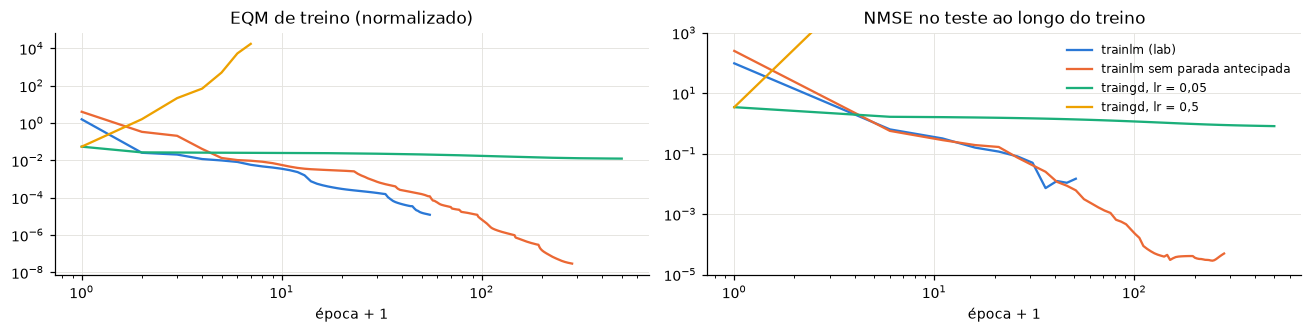

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.1))
for i, nome in enumerate(EXPERIMENTOS['3.5 treinamento']):  # a rede escolhida de cada variante
    rede = melhor(redes_exp[nome])
    h = np.array(rede.hist['treino'])
    ax[0].loglog(np.arange(1, len(h) + 1), h, color=COR[i], lw=1.5, label=nome)
    nm_ep = [nmse(rede(x_te, th), r_te) for th in rede.hist['th'][::5]]
    ax[1].loglog(np.arange(1, len(h) + 1, 5), nm_ep, color=COR[i], lw=1.5, label=nome)
ax[0].set(title='EQM de treino (normalizado)', xlabel='época + 1')
ax[1].set(title='NMSE no teste ao longo do treino', xlabel='época + 1', ylim=(1e-5, 1e3))
ax[1].legend(fontsize=8)
plt.tight_layout()

* **Parada antecipada.** Sem ela, o NMSE de teste da rede escolhida cai de 0,0143 para $5\times10^{-5}$, e a mediana cai de 0,0048 para $3\times10^{-4}$. Como os dados não têm ruído, a validação oscila e interrompe o treinamento enquanto o erro de teste ainda diminui. Treinar por 500 épocas melhora o resultado, mas leva cerca de 8 a 10 vezes mais tempo.
* **`traingd` com lr = 0,05,** o valor que o lab define e que não tem efeito no `trainlm`. Em 500 épocas, o EQM de treino quase não cai e nenhuma inicialização converge: a rede escolhida tem NMSE de teste 0,82. O gradiente descendente com passo fixo é muito lento neste problema mal condicionado. O LM, que usa a curvatura $\mathbf J^\top\mathbf J$, chega a $10^{-4}$ em cerca de 50 épocas.
* **`traingd` com lr = 0,5:** diverge já nas primeiras épocas (o EQM de treino passa de $10^{-1}$ para $10^{4}$). A rede devolvida é a da época 0, a de menor erro de validação, ou seja, a rede sem treino.

## 4. Tarefa (3): LSTM, a calculadora binária (`RNN_binary_lstm.m`)

**O problema.** Somar dois inteiros de 8 bits, $a \in [1, 128]$ e $b \in [1, 127]$, lendo um bit de cada por vez, **do menos para o mais significativo**. A cada passo a entrada é $(a_t, b_t)$ e o alvo é o bit $c_t$ da soma. Para acertar, a rede precisa lembrar o **"vai-um"** do passo anterior.

**A célula LSTM** (equações (1)–(7) dos comentários do `.m`):

$$\begin{aligned}
\mathbf i_t &= \sigma(\mathbf x_t\mathbf X_i + \mathbf h_{t-1}\mathbf H_i + b_i) &&\text{porta de entrada}\\
\mathbf f_t &= \sigma(\mathbf x_t\mathbf X_f + \mathbf h_{t-1}\mathbf H_f + b_f) &&\text{porta de esquecimento}\\
\mathbf o_t &= \sigma(\mathbf x_t\mathbf X_o + \mathbf h_{t-1}\mathbf H_o + b_o) &&\text{porta de saída}\\
\mathbf g_t &= \tanh(\mathbf x_t\mathbf X_g + \mathbf h_{t-1}\mathbf H_g + b_g) &&\text{candidato}\\
\mathbf C_t &= \mathbf C_{t-1}\odot\mathbf f_t + \mathbf g_t\odot\mathbf i_t &&\text{estado da célula}\\
\mathbf h_t &= \tanh(\mathbf C_t)\odot\mathbf o_t, \qquad \hat c_t = \sigma(\mathbf h_t\,\mathbf w_{out})
\end{aligned}$$

Ao contrário da RNN do lab, aqui a memória fica no estado $\mathbf C_t$, que é atualizado de forma **aditiva** e controlado por portas sigmoides: $\mathbf f_t$ decide o que manter, $\mathbf i_t$ o que escrever e $\mathbf o_t$ o que expor.

**O treino do `.m`:** 32 unidades, pesos iniciais $U(-1, 1)$, uma soma sorteada por iteração (treino *online*), 9000 iterações, $\alpha = 0{,}1$. O erro de saída é `y - pred`, sem a derivada da sigmoide, que é o gradiente da entropia cruzada.

### 4.1 Tradução fiel do `RNN_binary_lstm.m`

In [13]:
sigmoid = lambda z: 1 / (1 + np.exp(-z))
BITS = 8


def bits(n, nb=BITS):
    # bits de n, do menos para o mais significativo (a ordem em que a rede lê)
    return (np.asarray(n)[..., None] >> np.arange(nb)) & 1


def para_int(bs):
    return (np.asarray(bs) * (1 << np.arange(np.shape(bs)[-1]))).sum(-1)


def sorteia_soma(rng):
    a, b = rng.integers(1, 129), rng.integers(1, 128)               # randi(round(255/2)), randi(floor(255/2))
    return a, b, np.stack([bits(a), bits(b)], -1)[None].astype(float), bits(a + b).astype(float)


def lstm_forward(p, X):
    # X: (N, T, 2) -> previsões (N, T) e estados de cada passo (lotes de N somas de uma vez)
    N, T, _ = X.shape
    h, C = np.zeros((N, p['Hi'].shape[0])), np.zeros((N, p['Hi'].shape[0]))
    st = {k: [] for k in 'ifogCH'}
    st['H'].append(h); st['C'].append(C)
    pred = []
    for t in range(T):
        x = X[:, t]
        i = sigmoid(x @ p['Xi'] + h @ p['Hi'] + p['bi'])               # (1)
        f = sigmoid(x @ p['Xf'] + h @ p['Hf'] + p['bf'])               # (2)
        o = sigmoid(x @ p['Xo'] + h @ p['Ho'] + p['bo'])               # (3)
        g = np.tanh(x @ p['Xg'] + h @ p['Hg'] + p['bg'])               # (4)
        C = C * f + g * i                                              # (5)
        h = np.tanh(C) * o                                             # (6)
        for k, v in zip('ifogCH', (i, f, o, g, C, h)):
            st[k].append(v)
        pred.append(sigmoid(h @ p['out'])[:, 0])                       # (7)
    return np.stack(pred, 1), st


def lstm_treinar(versao='lab', iters=9000, alpha=0.1, hd=32, semente=0, mostra=0):
    # versao='lab': igual ao .m.  versao='bptt': retropropagação completa no tempo, com a derivada correta de tanh(C).
    rng = np.random.default_rng(semente)
    U = lambda *s: 2 * rng.random(s) - 1
    p = {}
    for g in 'ifog':                                                   # mesma ordem de sorteio do .m
        p['X' + g], p['H' + g], p['b' + g] = U(2, hd), U(hd, hd), U(1)  # os vieses começam escalares
    p['out'] = U(hd, 1)
    erros = []
    for j in range(1, iters + 1):
        a_int, b_int, X, y = sorteia_soma(rng)
        pred, st = lstm_forward(p, X)
        delta = y - pred[0]                                            # output_deltas
        upd = {k: np.zeros_like(v) for k, v in p.items()}
        dh_fut, dC_fut = np.zeros((1, hd)), np.zeros((1, hd))          # future_H_diff (no .m fica sempre zero)
        for t in reversed(range(BITS)):
            x = X[:, t]
            I, F, O, G = (st[k][t] for k in 'ifog')
            C, C_ant, H, H_ant = st['C'][t + 1], st['C'][t], st['H'][t + 1], st['H'][t]
            upd['out'] += H.T * delta[t]                               # out_para_diff
            dH = delta[t] * p['out'].T                                 # H_t_diff
            if versao == 'lab':
                dO = dH * np.tanh(C) * O * (1 - O)
                dC = dH * O * (1 - C**2)                               # tan_h_output_to_derivative(C_t)
            else:
                dH = dH + dh_fut
                dO = dH * np.tanh(C) * O * (1 - O)
                dC = dH * O * (1 - np.tanh(C)**2) + dC_fut
            dF = dC * C_ant * F * (1 - F)
            dI = dC * G * I * (1 - I)
            dG = dC * I * (1 - G**2)
            for g, d in zip('ifog', (dI, dF, dO, dG)):
                upd['X' + g] += x.T @ d
                upd['H' + g] += H_ant.T @ d
                upd['b' + g] = upd['b' + g] + d[0]                     # escalar + vetor (1 x hd): o viés vira vetor
            if versao != 'lab':
                dh_fut = dI @ p['Hi'].T + dF @ p['Hf'].T + dO @ p['Ho'].T + dG @ p['Hg'].T
                dC_fut = dC * F
        for k in p:
            p[k] = p[k] + alpha * upd[k]
        if j % 10 == 0:
            erros.append(np.abs(delta).sum())                          # allErr
        if mostra and j % mostra == 0:
            d = para_int(np.round(pred[0]).astype(int))
            print(f'iteração {j:5d} | erro {np.abs(delta).sum():.4f} | previsto {np.binary_repr(d, 8)} | '
                  f'verdadeiro {np.binary_repr(a_int + b_int, 8)} | {a_int:3d} + {b_int:3d} = {d}')
    return p, np.array(erros)


p_lab, err_lab = lstm_treinar('lab', semente=0, mostra=1000)

iteração  1000 | erro 0.0399 | previsto 01100000 | verdadeiro 01100000 |  27 +  69 = 96


iteração  2000 | erro 0.0168 | previsto 01100010 | verdadeiro 01100010 |  16 +  82 = 98


iteração  3000 | erro 0.0059 | previsto 00100000 | verdadeiro 00100000 |  22 +  10 = 32


iteração  4000 | erro 3.9814 | previsto 10000101 | verdadeiro 01011101 |  75 +  18 = 133


iteração  5000 | erro 1.7776 | previsto 01101100 | verdadeiro 01011100 |  54 +  38 = 108


iteração  6000 | erro 0.1366 | previsto 01010101 | verdadeiro 01010101 |   5 +  80 = 85


iteração  7000 | erro 0.1847 | previsto 01100001 | verdadeiro 01100001 |   4 +  93 = 97


iteração  8000 | erro 0.0805 | previsto 10011110 | verdadeiro 10011110 |  58 + 100 = 158


iteração  9000 | erro 0.1359 | previsto 10101011 | verdadeiro 10101011 |  61 + 110 = 171


Em vez de olhar só a soma sorteada a cada 1000 iterações, a função abaixo avalia a rede treinada em **todas** as $128 \times 127 = 16\,256$ somas possíveis:

In [14]:
def avalia(forward, p):
    # todas as 128 x 127 somas do treino
    A, B = (v.ravel() for v in np.meshgrid(np.arange(1, 129), np.arange(1, 128), indexing='ij'))
    X = np.stack([bits(A), bits(B)], -1).astype(float)
    pred, _ = forward(p, X)
    certo = np.round(pred).astype(int) == bits(A + B)
    return {'bits certos (%)': 100 * certo.mean(), 'somas exatas (%)': 100 * certo.all(1).mean()}


print({k: round(v, 2) for k, v in avalia(lstm_forward, p_lab).items()})

{'bits certos (%)': np.float64(99.68), 'somas exatas (%)': np.float64(98.26)}


### 4.2 Revisão do código e versão corrigida

Comparado à LSTM de livro-texto, o `RNN_binary_lstm.m` tem duas diferenças que afetam o treino:

1. **Retropropagação truncada em um passo.** As linhas com `future_H_diff` e `C_t_1_diff` estão comentadas, então o erro do passo $t$ não volta para os passos anteriores. Os pesos recorrentes $\mathbf H_*$ aprendem a *usar* $\mathbf h_{t-1}$, mas nada ensina a rede a *guardar* o vai-um em $\mathbf h_{t-1}$ ou $\mathbf C_{t-1}$.
2. **Derivada errada.** `tan_h_output_to_derivative(C_t)` calcula $1 - \mathbf C_t^2$, mas a derivada de $\tanh(\mathbf C_t)$ é $1 - \tanh^2(\mathbf C_t)$. As duas expressões só coincidem para $\mathbf C_t \approx 0$; para $|C_t| > 1$, $1 - C_t^2$ fica negativa e inverte o sentido da atualização no caminho da célula.

A versão `'bptt'` corrige as duas: retropropagação completa no tempo (BPTT) com a derivada certa. Para comparar, entram também duas **RNNs sem portas**, $\mathbf h_t = f(\mathbf x_t\mathbf X + \mathbf h_{t-1}\mathbf H + \mathbf b)$, com o mesmo tamanho, a mesma inicialização, o mesmo $\alpha$ e BPTT: uma com $f$ = sigmoide e outra com $f$ = tanh, a ativação da RNN do lab. Cada modelo é treinado a partir de 5 sementes.

In [15]:
def rnn_forward(p, X, f=None):
    f = f or {'sigmoide': sigmoid, 'tanh': np.tanh}[p['ativ']]
    h = np.zeros((X.shape[0], p['H'].shape[0]))
    Hs, pred = [h], []
    for t in range(X.shape[1]):
        h = f(X[:, t] @ p['X'] + h @ p['H'] + p['b'])
        Hs.append(h)
        pred.append(sigmoid(h @ p['out'])[:, 0])
    return np.stack(pred, 1), {'H': Hs}


def rnn_treinar(ativ='sigmoide', iters=9000, alpha=0.1, hd=32, semente=0):
    rng = np.random.default_rng(semente)
    U = lambda *s: 2 * rng.random(s) - 1
    p = {'X': U(2, hd), 'H': U(hd, hd), 'b': U(hd), 'out': U(hd, 1)}
    df = (lambda h: h * (1 - h)) if ativ == 'sigmoide' else (lambda h: 1 - h**2)
    erros = []
    for j in range(1, iters + 1):
        _, _, X, y = sorteia_soma(rng)
        pred, st = rnn_forward({**p, 'ativ': ativ}, X)
        delta = y - pred[0]
        upd = {k: np.zeros_like(v) for k, v in p.items()}
        dh_fut = np.zeros((1, hd))
        for t in reversed(range(BITS)):
            H, H_ant = st['H'][t + 1], st['H'][t]
            upd['out'] += H.T * delta[t]
            dA = (delta[t] * p['out'].T + dh_fut) * df(H)
            upd['X'] += X[:, t].T @ dA
            upd['H'] += H_ant.T @ dA
            upd['b'] += dA[0]
            dh_fut = dA @ p['H'].T
        for k in p:
            p[k] = p[k] + alpha * upd[k]
        if j % 10 == 0:
            erros.append(np.abs(delta).sum())
    p['ativ'] = ativ
    return p, np.array(erros)


MODELOS = {'LSTM do lab': ('lstm', 'lab'), 'LSTM corrigida (BPTT)': ('lstm', 'bptt'),
           'RNN sem portas, sigmoide': ('rnn', 'sigmoide'), 'RNN sem portas, tanh': ('rnn', 'tanh')}


def _treina_bin(tarefa):
    nome, s = tarefa
    tipo, var = MODELOS[nome]
    if tipo == 'lstm':
        return lstm_treinar(var, semente=s)
    return rnn_treinar(var, semente=s)


t0 = time.perf_counter()
tarefas = [(nome, s) for nome in MODELOS for s in SEMENTES]
if N_PROC > 1:
    with ProcessPoolExecutor(N_PROC, mp_context=mp.get_context('fork')) as ex:
        saidas = list(ex.map(_treina_bin, tarefas))
else:
    saidas = [_treina_bin(t) for t in tarefas]
bin_res = {}
for (nome, s), saida in zip(tarefas, saidas):
    bin_res.setdefault(nome, []).append(saida)
print(f'{len(tarefas)} redes treinadas em {time.perf_counter() - t0:.0f} s')

linhas = []
for nome, res in bin_res.items():
    fwd = lstm_forward if MODELOS[nome][0] == 'lstm' else rnn_forward
    a8 = [avalia(fwd, p) for p, _ in res]
    faixa = lambda v: f'{np.mean(v):.1f} ({np.min(v):.1f}–{np.max(v):.1f})'
    linhas.append({'modelo': nome, '8 bits: bits certos (%)': faixa([a['bits certos (%)'] for a in a8]),
                   '8 bits: somas exatas (%)': faixa([a['somas exatas (%)'] for a in a8]),
                   'erro final (média das últimas 500 iterações)': f"{np.mean([e[-50:].mean() for _, e in res]):.3f}"})
print('média (mínimo–máximo) entre as 5 sementes')
display(pd.DataFrame(linhas).set_index('modelo'))

20 redes treinadas em 11 s


média (mínimo–máximo) entre as 5 sementes


,8 bits: bits certos (%),8 bits: somas exatas (%),erro final (média das últimas 500 iterações)
modelo,,,
LSTM do lab,99.1 (96.0–100.0),95.4 (81.7–100.0),0.202
LSTM corrigida (BPTT),100.0 (100.0–100.0),100.0 (100.0–100.0),0.003
"RNN sem portas, sigmoide",100.0 (100.0–100.0),100.0 (100.0–100.0),0.009
"RNN sem portas, tanh",57.6 (56.3–59.3),0.6 (0.0–1.7),3.467


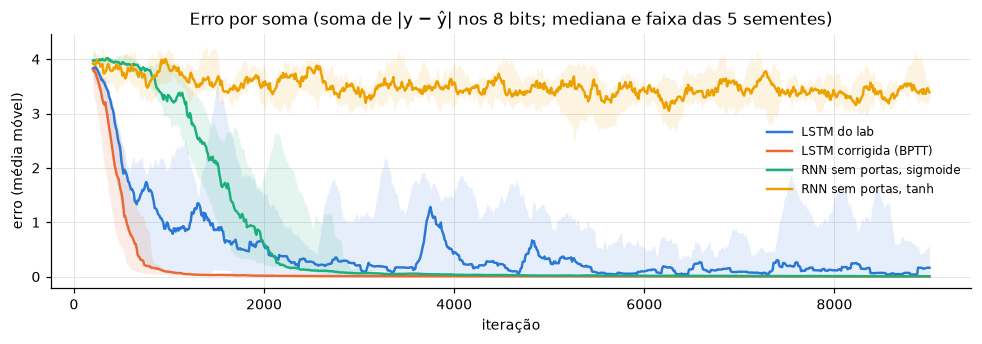

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.2))
suave = lambda e: np.convolve(e, np.ones(20) / 20, mode='valid')
for i, (nome, res) in enumerate(bin_res.items()):
    curvas = np.array([suave(e) for _, e in res])
    it = (np.arange(curvas.shape[1]) + 20) * 10
    ax.plot(it, np.median(curvas, 0), color=COR[i], lw=1.6, label=nome)
    ax.fill_between(it, curvas.min(0), curvas.max(0), color=COR[i], alpha=0.12, lw=0)
ax.set(title='Erro por soma (soma de |y − ŷ| nos 8 bits; mediana e faixa das 5 sementes)', xlabel='iteração', ylabel='erro (média móvel)')
ax.legend(fontsize=8)
plt.tight_layout()

* **LSTM do lab (tradução fiel).** A rede aprende a somar: na semente 0, acerta 98,3 % das 16 256 somas e 99,7 % dos bits. Mas o treino é instável, com recaídas perto das iterações 4000 e 5000 (também visíveis na impressão acima), e varia muito entre sementes: de 82 % a 100 % de somas exatas.
* **LSTM corrigida (BPTT).** Converge em cerca de 1000 iterações, sem recaídas, e acerta 100 % das somas em todas as sementes. A instabilidade da versão do lab vem, portanto, das duas diferenças do código, e não da arquitetura LSTM.
* **RNN sem portas, sigmoide.** Também chega a 100 %, só que mais devagar (cerca de 3000 iterações). Isso é esperado: o vai-um é uma dependência de **um passo**, curta demais para o gradiente de uma RNN simples desaparecer. A vantagem decisiva da LSTM aparece em dependências longas, de dezenas a centenas de passos. Nesse caso, o estado de célula aditivo $\mathbf C_t = \mathbf f_t\odot\mathbf C_{t-1} + \mathbf g_t\odot\mathbf i_t$ deixa o erro fluir para trás sem ser multiplicado a cada passo por $\mathbf R$ e pela derivada da ativação.
* **RNN sem portas, tanh.** Não aprende: acerta 0,6 % das somas e 58 % dos bits, pouco acima do acaso (50 %), com a mesma inicialização $U(-1, 1)$ e o mesmo $\alpha = 0{,}1$ que funcionam com a sigmoide. A explicação provável é o ganho da recorrência. Com 32 unidades e pesos $U(-1, 1)$, o raio espectral de $\mathbf H$ é cerca de $\sqrt{32/3} \approx 3{,}3$. Com a sigmoide, cuja derivada é no máximo 0,25, o ganho fica abaixo de 1 ($0{,}25 \times 3{,}3 \approx 0{,}8$) e o gradiente retropropagado tende a decair a cada passo. Com a tanh, cuja derivada chega a 1, o ganho pode chegar a 3,3 e o gradiente cresce, deixando as atualizações grandes demais para esse $\alpha$. A LSTM, que também tem tanh internas, treinou com o mesmo $\alpha$.

## 5. Conclusões

1. **Tarefa (1).** No caso causal ($D = 0$), a RNN usada para imitar a convolução atinge NMSE ≈ 0,32 porque não vê os valores futuros da refletividade necessários para gerar a parte inicial da wavelet. Com 10 amostras de antecipação, reproduz a wavelet inteira e o NMSE cai para cerca de $2\times10^{-6}$.
2. **Tarefa (2).**
   * A capacidade mínima fica entre 2 e 5 neurônios. Mais neurônios, mais atrasos de realimentação e antecipação $D$ reduzem o erro, até $10^{-5}$–$10^{-6}$; a profundidade não ajudou.
   * Sem recorrência, a rede não deconvolve (NMSE ≈ 0,5): a memória é essencial.
   * O algoritmo de treino pesou mais que a arquitetura. O `trainlm` chega a $10^{-4}$ em cerca de 50 épocas. O `traingd` com o `lr = 0.05` do lab quase não avança em 500 épocas, e com lr = 0,5 diverge. A parada antecipada, com dados sem ruído, só atrapalhou.
3. **Tarefa (3).** A LSTM do lab aprende a somar (95 % das somas exatas, em média), mas o treino é instável e varia entre sementes (82 % a 100 %). O código tem retropropagação truncada em um passo e uma derivada errada, que inverte o sentido da atualização quando $|C_t| > 1$. Com as duas correções, a LSTM acerta 100 % das somas em todas as sementes. Como a dependência do problema é de um passo, uma RNN sem portas com sigmoide também o resolve; com tanh e o mesmo $\alpha$, não aprende. A vantagem da LSTM aparece em dependências longas, que nem a soma binária nem a deconvolução do lab (wavelet de cerca de 20 amostras) exigem.